# Task 4: Classification with Logistic Regression

## AI & ML Internship – Elevate Labs

### Objective
To build a binary classification model using Logistic Regression.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve
)

In [2]:
from google.colab import files
uploaded = files.upload()

Saving data.csv to data.csv


In [25]:
df = pd.read_csv("data.csv")
print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())
df.head()

Dataset Shape: (569, 33)

Column Names:
['id', 'diagnosis', 'radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se', 'fractal_dimension_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave points_worst', 'symmetry_worst', 'fractal_dimension_worst', 'Unnamed: 32']


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [7]:
df = df.drop(columns=['id', 'Unnamed: 32'])

print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:", df.duplicated().sum())

print("\nTarget Distribution:")
print(df['diagnosis'].value_counts())

Missing Values:
diagnosis                  0
radius_mean                0
texture_mean               0
perimeter_mean             0
area_mean                  0
smoothness_mean            0
compactness_mean           0
concavity_mean             0
concave points_mean        0
symmetry_mean              0
fractal_dimension_mean     0
radius_se                  0
texture_se                 0
perimeter_se               0
area_se                    0
smoothness_se              0
compactness_se             0
concavity_se               0
concave points_se          0
symmetry_se                0
fractal_dimension_se       0
radius_worst               0
texture_worst              0
perimeter_worst            0
area_worst                 0
smoothness_worst           0
compactness_worst          0
concavity_worst            0
concave points_worst       0
symmetry_worst             0
fractal_dimension_worst    0
dtype: int64

Duplicate Records: 0

Target Distribution:
diagnosis
B    357
M    212


In [11]:
X=df.drop('diagnosis',axis=1)
y=df['diagnosis']

In [12]:
y=y.map({'B':0,'M':1})

In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [17]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [18]:
print("Training Features Shape:", X_train_scaled.shape)
print("Testing Features Shape:", X_test_scaled.shape)
print("Training Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)

Training Features Shape: (455, 30)
Testing Features Shape: (114, 30)
Training Target Shape: (455,)
Testing Target Shape: (114,)


In [19]:
model = LogisticRegression(random_state=42)
model.fit(X_train_scaled, y_train)

LogisticRegression(random_state=42)

In [20]:
y_pred = model.predict(X_test_scaled)
y_prob = model.predict_proba(X_test_scaled)[:, 1]

In [21]:
# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

# Precision
precision = precision_score(y_test, y_pred)
print("\nPrecision:", precision)

# Recall
recall = recall_score(y_test, y_pred)
print("Recall:", recall)

# ROC-AUC Score
roc_auc = roc_auc_score(y_test, y_prob)
print("ROC-AUC Score:", roc_auc)

Confusion Matrix:
[[71  1]
 [ 3 39]]

Precision: 0.975
Recall: 0.9285714285714286
ROC-AUC Score: 0.996031746031746


In [22]:
thresholds = [0.3, 0.4, 0.5, 0.6, 0.7]

for threshold in thresholds:
    y_pred_threshold = (y_prob >= threshold).astype(int)

    precision = precision_score(y_test, y_pred_threshold)
    recall = recall_score(y_test, y_pred_threshold)

    print("Threshold:", threshold)
    print("Precision:", round(precision, 4))
    print("Recall:", round(recall, 4))
    print("-" * 30)

Threshold: 0.3
Precision: 0.9762
Recall: 0.9762
------------------------------
Threshold: 0.4
Precision: 0.9756
Recall: 0.9524
------------------------------
Threshold: 0.5
Precision: 0.975
Recall: 0.9286
------------------------------
Threshold: 0.6
Precision: 1.0
Recall: 0.9048
------------------------------
Threshold: 0.7
Precision: 1.0
Recall: 0.9048
------------------------------


### Sigmoid Function

The sigmoid function converts the output of Logistic Regression into a probability between 0 and 1.

Its mathematical formula is:

\[
\sigma(z) = \frac{1}{1 + e^{-z}}
\]

- If the probability is 0.5 or higher, the default prediction is 1 (Malignant).
- If the probability is below 0.5, the default prediction is 0 (Benign).
- Changing the classification threshold changes how predictions are classified.

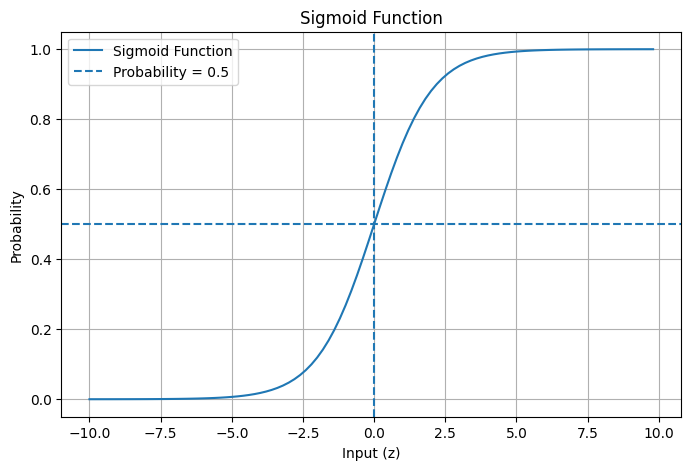

In [24]:
z = [i * 0.2 - 10 for i in range(100)]

sigmoid = [1 / (1 + 2.718281828 ** (-i)) for i in z]

plt.figure(figsize=(8, 5))
plt.plot(z, sigmoid, label='Sigmoid Function')

plt.axhline(y=0.5, linestyle='--', label='Probability = 0.5')
plt.axvline(x=0, linestyle='--')

plt.xlabel('Input (z)')
plt.ylabel('Probability')
plt.title('Sigmoid Function')
plt.legend()
plt.grid()
plt.show()